# Compare results from benchmarking experiments

Note that these numbers are from a single run per experiment, so small differences should not be considered statistically significant.

In [1]:
%%capture
%env AWS_PROFILE=kmnlp

In [2]:
import sys
sys.path.append("../src")

In [3]:
import json
import os
from pathlib import Path
from os.path import basename, dirname, splitext

import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from rich import print as rprint
from tqdm import tqdm

In [4]:
%matplotlib inline
sns.reset_defaults()

In [5]:
data_root = Path("./data")
benchmark_data_paths = data_root.glob("zarr_*.json")
benchmark_data = {}
for path in benchmark_data_paths:
    with open(path) as f:
        benchmark_data[path.stem] = json.load(f)

## Dataset opening time

In [6]:
ds_names = [basename(k) for k in benchmark_data["zarr_parquet"]["ds_zarr_file_bytes"].keys()]
ds_zarr_open_times = {k: list(v["ds_zarr_open_times"].values()) for k, v in benchmark_data.items()}

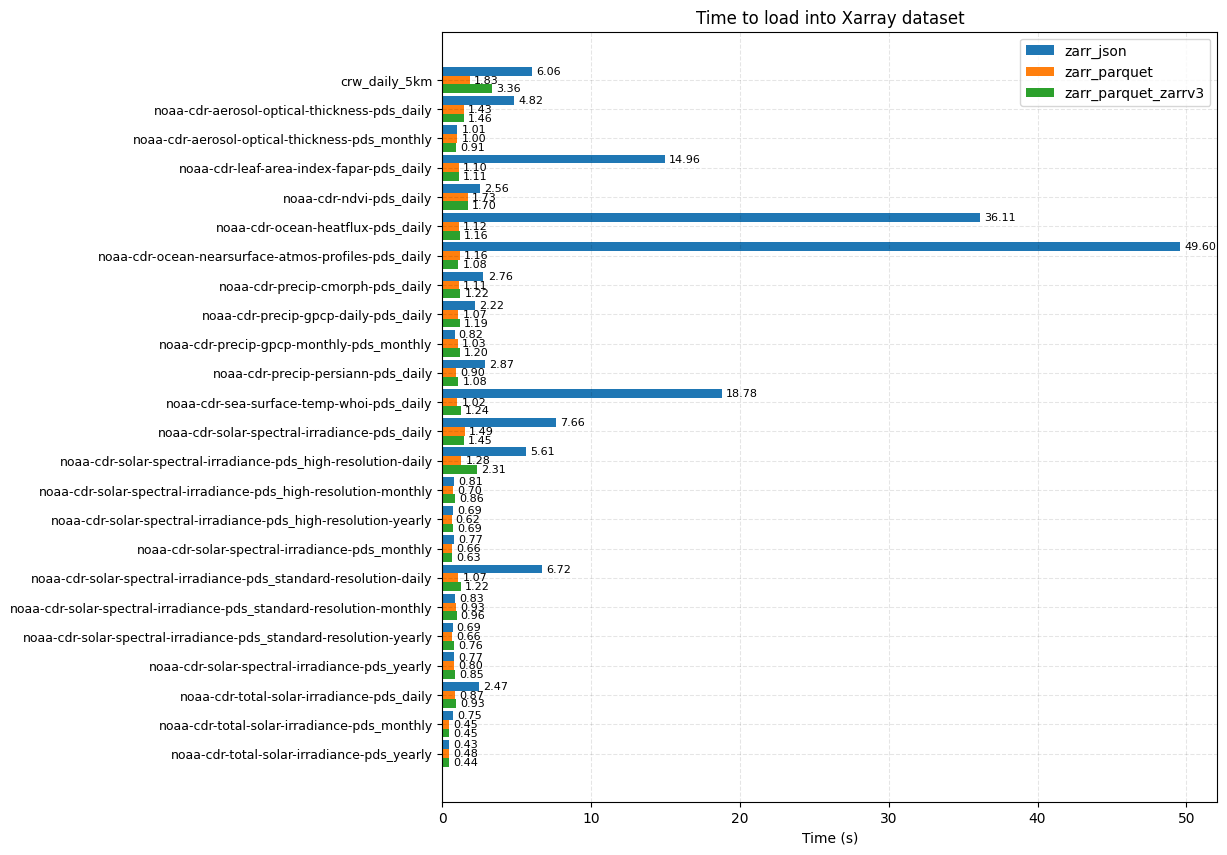

In [7]:
plt.close('all')
y = np.arange(len(ds_names)) + 0.1
width = 0.3
multiplier = 0

fig, ax = plt.subplots(figsize=(10, 10))

for exp, times in sorted(ds_zarr_open_times.items()):
    offset = width * multiplier
    rects = ax.barh(y=y + offset, width=times, height=width, label=exp)
    ax.bar_label(rects, padding=3, fmt="%.2f", fontsize=8)
    multiplier += 1

ax.set_title("Time to load into Xarray dataset")
ax.set_xlabel("Time (s)")
ax.set_yticks(y + width, ds_names, fontsize=9)
# ax.set_xscale("log")
ax.grid(ls="--", c="k", alpha=0.1)
ax.invert_yaxis()
ax.legend(loc="upper right")

plt.show()

## Computation time

In [8]:
ds_names = [basename(k) for k in benchmark_data["zarr_parquet"]["ds_zarr_file_bytes"].keys()]
ds_slice_max_info = {k: list(v["ds_slice_max_info"].values()) for k, v in benchmark_data.items()}

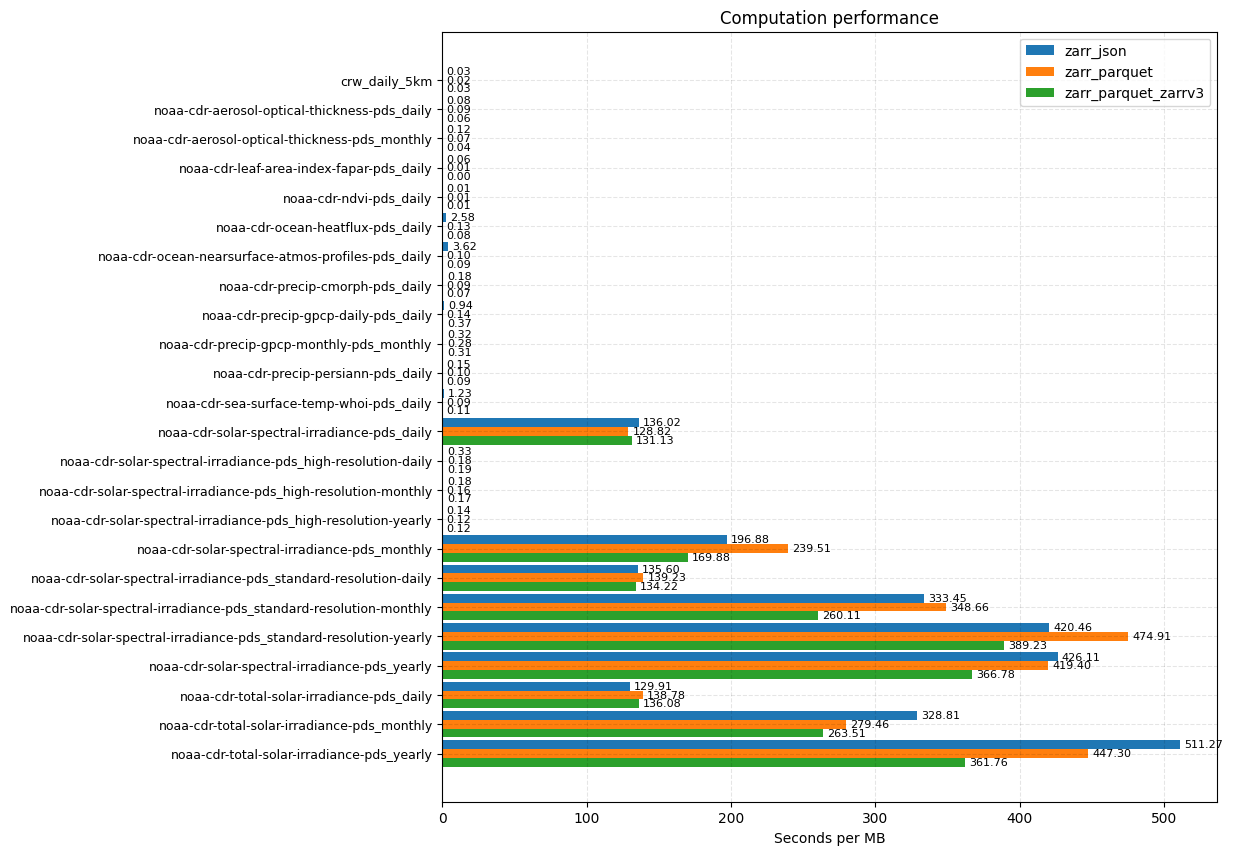

In [9]:
plt.close('all')
y = np.arange(len(ds_names)) + 0.1
width = 0.3
multiplier = 0

fig, ax = plt.subplots(figsize=(10, 10))

for exp, infos in sorted(ds_slice_max_info.items()):
    offset = width * multiplier
    nbytes = np.array([info["bytes"] for info in infos])
    times = np.array([info["time"] for info in infos])
    seconds_per_mb = times / (nbytes / 2**20)
    rects = ax.barh(y=y + offset, width=seconds_per_mb, height=width, label=exp)
    ax.bar_label(rects, padding=3, fmt="%.2f", fontsize=8)
    multiplier += 1

ax.set_title("Computation performance")
ax.set_xlabel("Seconds per MB")
ax.set_yticks(y + width, ds_names, fontsize=9)
# ax.set_xscale("log")
ax.grid(ls="--", c="k", alpha=0.1)
ax.invert_yaxis()
ax.legend(loc="upper right")

plt.show()

### Without small (<1MB) datasets

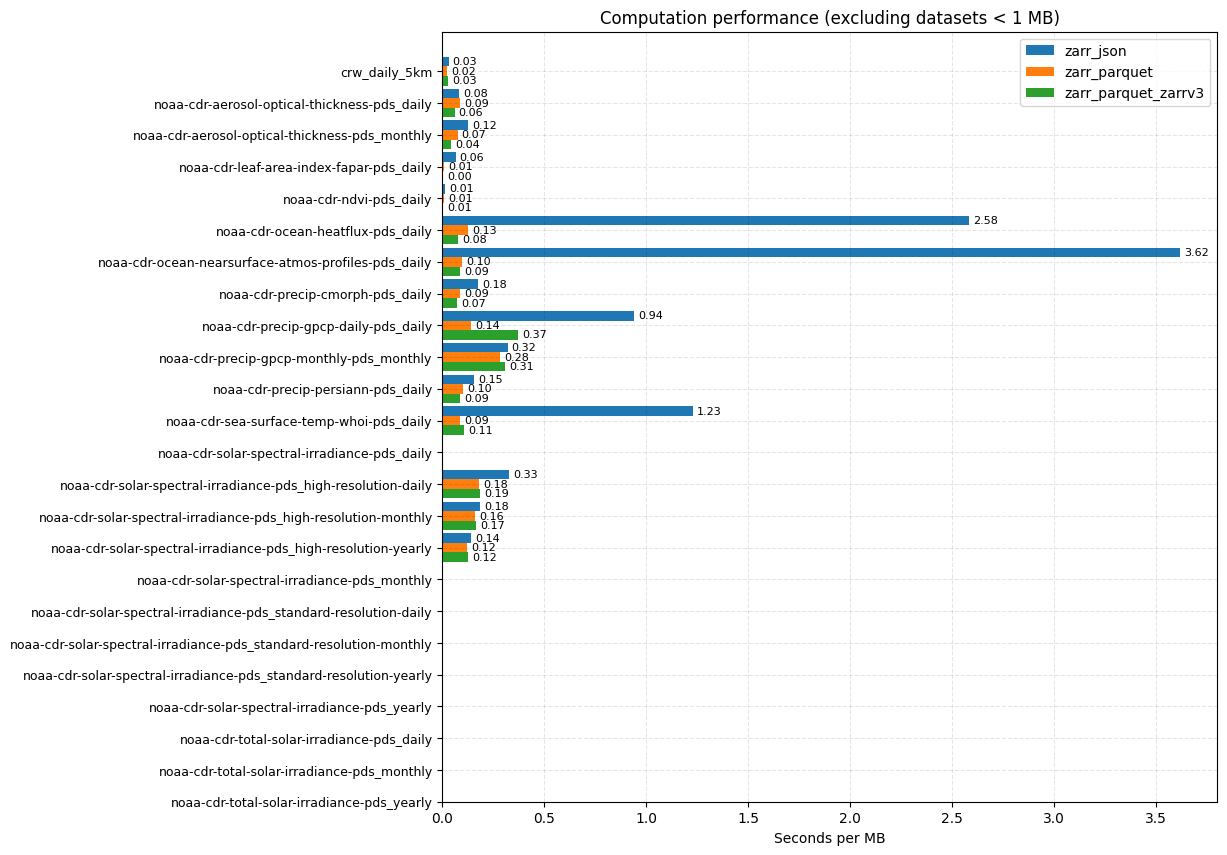

In [10]:
plt.close('all')
y = np.arange(len(ds_names)) + 0.1
width = 0.3
multiplier = 0

fig, ax = plt.subplots(figsize=(10, 10))

for exp, infos in sorted(ds_slice_max_info.items()):
    offset = width * multiplier
    nbytes = np.array([info["bytes"] for info in infos])
    mbs = nbytes / 2**20
    times = np.array([info["time"] for info in infos])
    seconds_per_mb = times / mbs
    mask = mbs >= 1
    rects = ax.barh(y=y[mask] + offset, width=seconds_per_mb[mask], height=width, label=exp)
    ax.bar_label(rects, padding=3, fmt="%.2f", fontsize=8)
    multiplier += 1

ax.set_title("Computation performance (excluding datasets < 1 MB)")
ax.set_xlabel("Seconds per MB")
ax.set_yticks(y + width, ds_names, fontsize=9)
# ax.set_xscale("log")
ax.grid(ls="--", c="k", alpha=0.1)
ax.invert_yaxis()
ax.legend(loc="upper right")

plt.show()

### Actual times for small (<1MB datasets)

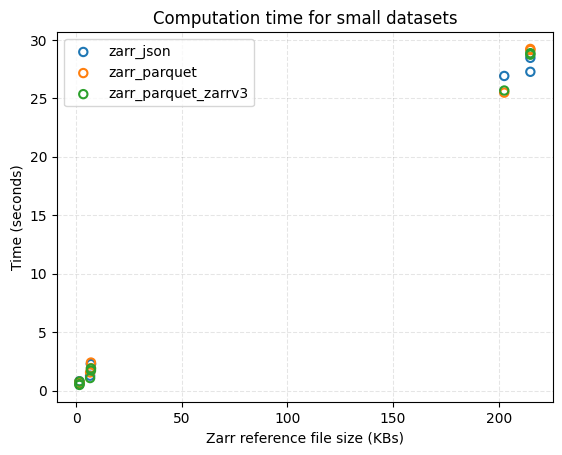

In [16]:
plt.close('all')

fig, ax = plt.subplots()

cmap = plt.get_cmap("tab10")
exp_to_c = {k: cmap(i) for i, k in enumerate(sorted(benchmark_data))}

for exp, infos in sorted(ds_slice_max_info.items()):
    nbytes = np.array([info["bytes"] for info in infos])
    times = np.array([info["time"] for info in infos])
    mbs = nbytes / 2**20
    kbs = nbytes / 2**10
    seconds_per_mb = times / mbs
    mask = mbs < 1
    ax.scatter(
        kbs[mask], 
        times[mask], 
        label=exp, 
        marker="o", 
        fc="none", 
        ec=[exp_to_c[exp]]*mask.sum(), 
        lw=1.5
    )

ax.set_xlabel("Zarr reference file size (KBs)")
ax.set_ylabel("Time (seconds)")
ax.set_title("Computation time for small datasets")
plt.grid(ls="--", c="k", alpha=0.1)
ax.legend()

plt.show()